# Métodos Cuasi-Newtonianos, Algoritmo BFGS y Método de Newton-CG
**Universidad Mayor de San Andrés — Facultad de Ciencias Puras y Naturales — Carrera de Informática**
**Materia:** Métodos Numéricos II (`DAT-252`) | **Docente:** M.Sc. Carlos Mullisaca Choque
**Estudiantes:** Gómez Mallo, Maximiliano · Medina Balboa, Iver Samuel

---

Este notebook implementa **desde cero** (en NumPy puro, validando contra `scipy.optimize.minimize`) todos los algoritmos analizados en el informe y la exposición:
1. **Búsquedas de línea**: Armijo con retroceso (*backtracking*) y Condiciones de Wolfe Fuertes (Algoritmos 3.5 y 3.6 de Nocedal & Wright).
2. **Métodos de optimización irrestricta**:
   - Descenso de Gradiente (primer orden).
   - Cuasi-Newton **DFP** y **BFGS** (actualización directa de $H_k$ en $O(n^2)$ por Sherman–Morrison–Woodbury).
   - **L-BFGS** (memoria limitada, recursión de dos bucles en $O(mn)$).
   - **Newton-CG** (Newton truncado / inexacto, tanto con producto Hessiana-vector analítico como *Hessian-Free* por diferencias finitas, y detección de curvatura negativa $d_j^T \nabla^2 f(x_k) d_j \le 0$).
3. **Experimentos reproducibles** que generan todas las tablas y figuras (`figuras/*.png`) del informe.

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

os.makedirs("figuras", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 220,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "-",
    "legend.fontsize": 9.2,
})
print("Entorno listo. NumPy:", np.__version__)

Entorno listo. NumPy: 2.5.5


## 1. Búsquedas de Línea: Armijo y Condiciones de Wolfe Fuertes

En métodos Cuasi-Newtonianos (especialmente BFGS y DFP), satisfacer la **condición de curvatura** $s_k^T y_k > 0$ es indispensable para preservar la definitud positiva de $H_{k+1}$. Las **Condiciones de Wolfe Fuertes**:
$$f(x_k + \alpha p_k) \le f(x_k) + c_1 \alpha \nabla f_k^T p_k, \qquad \left|\nabla f(x_k + \alpha p_k)^T p_k\right| \le c_2 \left|\nabla f_k^T p_k\right|$$
con $0 < c_1 < c_2 < 1$ (típicamente $c_1 = 10^{-4}$, $c_2 = 0.9$), garantizan automáticamente $s_k^T y_k \ge -(1 - c_2)\alpha_k \nabla f_k^T p_k > 0$.

In [2]:
def backtracking_armijo(f, x, p, fx, gx, c1=1e-4, rho=0.5, alpha_init=1.0, max_iter=40):
    dg0 = float(np.dot(gx, p))
    alpha = alpha_init
    ef = 0
    eps_f = 1e-14 * max(1.0, abs(fx))
    for _ in range(max_iter):
        fn = float(f(x + alpha * p))
        ef += 1
        if fn <= fx + c1 * alpha * dg0 + eps_f:
            return alpha, fn, ef
        alpha *= rho
    return alpha, float(f(x + alpha * p)), ef + 1


def _zoom(f, g, x, p, f0, dg0, alo, ahi, flo, c1, c2, max_iter=25):
    ef, eg = 0, 0
    eps_f = 1e-14 * max(1.0, abs(f0))
    a = 0.5 * (alo + ahi)
    for _ in range(max_iter):
        a = 0.5 * (alo + ahi)
        xn = x + a * p
        fa = float(f(xn)); ef += 1
        if (fa > f0 + c1 * a * dg0 + eps_f) or (fa >= flo + eps_f and alo > 0.0):
            ahi = a
        else:
            ga = np.asarray(g(xn), dtype=float); eg += 1
            dga = float(np.dot(ga, p))
            if abs(dga) <= -c2 * dg0:
                return a, fa, ga, ef, eg
            if dga * (ahi - alo) >= 0.0:
                ahi = alo
            alo, flo = a, fa
        if abs(ahi - alo) < 1e-11 * max(1.0, abs(alo)):
            break
    xn = x + a * p
    return a, float(f(xn)), np.asarray(g(xn), dtype=float), ef + 1, eg + 1


def wolfe_line_search(f, g, x, p, f0, g0, c1=1e-4, c2=0.9, alpha_init=1.0, max_iter=25):
    # Algoritmos 3.5 y 3.6 de Nocedal & Wright (2006) con salvaguarda de punto flotante
    dg0 = float(np.dot(g0, p))
    if dg0 >= 0.0:
        p = -g0
        dg0 = float(np.dot(g0, p))
    ef, eg = 0, 0
    eps_f = 1e-14 * max(1.0, abs(f0))
    a_prev, f_prev = 0.0, f0
    a = alpha_init
    for i in range(max_iter):
        xn = x + a * p
        fa = float(f(xn)); ef += 1
        if (fa > f0 + c1 * a * dg0 + eps_f) or (i > 0 and fa >= f_prev + eps_f):
            az, fz, gz, efz, egz = _zoom(f, g, x, p, f0, dg0, a_prev, a, f_prev, c1, c2)
            return az, fz, gz, ef + efz, eg + egz
        ga = np.asarray(g(xn), dtype=float); eg += 1
        dga = float(np.dot(ga, p))
        if abs(dga) <= -c2 * dg0:
            return a, fa, ga, ef, eg
        if dga >= 0.0:
            az, fz, gz, efz, egz = _zoom(f, g, x, p, f0, dg0, a, a_prev, fa, c1, c2)
            return az, fz, gz, ef + efz, eg + egz
        a_prev, f_prev = a, fa
        a *= 2.0
    xn = x + a * p
    return a, float(f(xn)), np.asarray(g(xn), dtype=float), ef + 1, eg + 1

## 2. Implementación de los Métodos: GD, DFP, BFGS, L-BFGS y Newton-CG

En **BFGS**, aplicamos la identidad de Sherman–Morrison–Woodbury para actualizar directamente la inversa aproximada $H_k \approx [\nabla^2 f(x_k)]^{-1}$ en $O(n^2)$ operaciones por iteración:
$$H_{k+1} = \left(I - \rho_k s_k y_k^T\right) H_k \left(I - \rho_k y_k s_k^T\right) + \rho_k s_k s_k^T, \qquad \rho_k = \frac{1}{y_k^T s_k}.$$

En **Newton-CG**, resolvemos de forma aproximada el sistema $\nabla^2 f(x_k) p_k = -\nabla f(x_k)$ con Gradiente Conjugado hasta que $\|r_j\| \le \eta_k \|\nabla f_k\|$, deteniendo inmediatamente CG si aparece **curvatura negativa** $d_j^T \nabla^2 f(x_k) d_j \le 0$.

In [3]:
def descenso_gradiente(f, g, x0, tol=1e-8, max_iter=5000):
    x = np.array(x0, dtype=float)
    fx = float(f(x)); gx = np.asarray(g(x), dtype=float)
    ef, eg = 1, 1
    hist = [{"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx))}]
    for _ in range(max_iter):
        if np.linalg.norm(gx) < tol:
            break
        p = -gx
        a, fx, efs = backtracking_armijo(f, x, p, fx, gx)
        ef += efs
        x = x + a * p
        gx = np.asarray(g(x), dtype=float); eg += 1
        hist.append({"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx))})
    return x, hist, {"ef": ef, "eg": eg, "iters": len(hist) - 1}


def cuasi_newton_dfp(f, g, x0, tol=1e-8, max_iter=500):
    x = np.array(x0, dtype=float)
    n = len(x)
    fx = float(f(x)); gx = np.asarray(g(x), dtype=float)
    H = np.eye(n)
    ef, eg = 1, 1
    hist = [{"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx)), "alpha": 0.0, "sy": 0.0}]
    for k in range(max_iter):
        if np.linalg.norm(gx) < tol:
            break
        p = -(H @ gx)
        a, fn, gn, efs, egs = wolfe_line_search(f, g, x, p, fx, gx)
        ef += efs; eg += egs
        xn = x + a * p
        s = xn - x; y = gn - gx
        sy = float(np.dot(s, y))
        if sy > 1e-16:
            if k == 0:
                H = (sy / float(np.dot(y, y))) * np.eye(n)
            Hy = H @ y
            yHy = float(np.dot(y, Hy))
            if yHy > 1e-20:
                H = H + np.outer(s, s) / sy - np.outer(Hy, Hy) / yHy
        x, fx, gx = xn, fn, gn
        hist.append({"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx)), "alpha": a, "sy": sy})
    return x, hist, {"ef": ef, "eg": eg, "iters": len(hist) - 1}


def cuasi_newton_bfgs(f, g, x0, tol=1e-8, max_iter=500, track_eigs=False):
    x = np.array(x0, dtype=float)
    n = len(x)
    fx = float(f(x)); gx = np.asarray(g(x), dtype=float)
    H = np.eye(n)
    ef, eg = 1, 1
    hist = [{
        "x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx)),
        "alpha": 0.0, "sy": 0.0,
        "lmin": float(np.min(np.linalg.eigvalsh(H))) if track_eigs else None
    }]
    for k in range(max_iter):
        if np.linalg.norm(gx) < tol:
            break
        p = -(H @ gx)
        a, fn, gn, efs, egs = wolfe_line_search(f, g, x, p, fx, gx)
        ef += efs; eg += egs
        xn = x + a * p
        s = xn - x; y = gn - gx
        sy = float(np.dot(s, y))
        if sy > 1e-16:
            if k == 0:
                H = (sy / float(np.dot(y, y))) * np.eye(n)
            rho = 1.0 / sy
            Hy = H @ y
            yHy = float(np.dot(y, Hy))
            # Actualizacion BFGS en O(n^2) equivalente a (I - rho s y^T) H (I - rho y s^T) + rho s s^T
            H = H + rho * (1.0 + rho * yHy) * np.outer(s, s) - rho * (np.outer(Hy, s) + np.outer(s, Hy))
        x, fx, gx = xn, fn, gn
        hist.append({
            "x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx)),
            "alpha": a, "sy": sy,
            "lmin": float(np.min(np.linalg.eigvalsh(H))) if track_eigs else None
        })
    return x, hist, {"ef": ef, "eg": eg, "iters": len(hist) - 1}


def l_bfgs(f, g, x0, m=10, tol=1e-8, max_iter=500):
    x = np.array(x0, dtype=float)
    fx = float(f(x)); gx = np.asarray(g(x), dtype=float)
    ef, eg = 1, 1
    S, Y, R = [], [], []
    hist = [{"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx))}]
    for _ in range(max_iter):
        if np.linalg.norm(gx) < tol:
            break
        # Recursion de dos bucles (Nocedal & Wright Alg. 7.4)
        q = gx.copy()
        alphas = []
        for s_i, y_i, rho_i in reversed(list(zip(S, Y, R))):
            ai = rho_i * float(np.dot(s_i, q))
            alphas.append(ai)
            q = q - ai * y_i
        if S:
            gamma = float(np.dot(S[-1], Y[-1])) / max(float(np.dot(Y[-1], Y[-1])), 1e-20)
            r = gamma * q
        else:
            r = q
        for (s_i, y_i, rho_i), ai in zip(zip(S, Y, R), reversed(alphas)):
            beta = rho_i * float(np.dot(y_i, r))
            r = r + s_i * (ai - beta)
        p = -r
        a, fn, gn, efs, egs = wolfe_line_search(f, g, x, p, fx, gx)
        ef += efs; eg += egs
        xn = x + a * p
        s = xn - x; y = gn - gx
        sy = float(np.dot(s, y))
        if sy > 1e-16:
            if len(S) == m:
                S.pop(0); Y.pop(0); R.pop(0)
            S.append(s); Y.append(y); R.append(1.0 / sy)
        x, fx, gx = xn, fn, gn
        hist.append({"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx))})
    return x, hist, {"ef": ef, "eg": eg, "iters": len(hist) - 1}


def make_fd_hessp(g):
    # Producto Hessiana-vector sin formar la Hessiana (Hessian-Free)
    eps_sqrt = np.sqrt(np.finfo(float).eps)
    def hessp(x, d, gx=None):
        nd = float(np.linalg.norm(d))
        if nd == 0.0:
            return np.zeros_like(x)
        h = eps_sqrt / nd
        if gx is None:
            gx = np.asarray(g(x), dtype=float)
        return (np.asarray(g(x + h * d), dtype=float) - gx) / h
    return hessp


def newton_cg(f, g, hessp, x0, tol=1e-8, max_iter=300, max_cg=None, forcing="superlinear"):
    x = np.array(x0, dtype=float)
    n = len(x)
    if max_cg is None:
        max_cg = max(2 * n, 20)
    fx = float(f(x)); gx = np.asarray(g(x), dtype=float)
    ef, eg, hv_cnt, neg_cnt = 1, 1, 0, 0
    hist = [{"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx)), "cg": 0, "neg": False, "alpha": 0.0}]
    for _ in range(max_iter):
        ng = float(np.linalg.norm(gx))
        if ng < tol:
            break
        if forcing == "superlinear":
            eta = min(0.5, np.sqrt(ng))
        elif forcing == "quadratic":
            eta = min(0.5, ng)
        elif isinstance(forcing, (int, float)):
            eta = float(forcing)
        else:
            eta = min(0.5, np.sqrt(ng))
        cg_tol = eta * ng

        z = np.zeros(n)
        r = gx.copy()
        d = -r.copy()
        cg_iters = 0
        neg_curv = False
        p = None
        for j in range(max_cg):
            Hd = hessp(x, d, gx); hv_cnt += 1
            dHd = float(np.dot(d, Hd)); cg_iters += 1
            if dHd <= 0.0:
                neg_curv = True; neg_cnt += 1
                p = -gx.copy() if j == 0 else z.copy()
                break
            rr = float(np.dot(r, r))
            alpha_cg = rr / dHd
            z = z + alpha_cg * d
            r = r + alpha_cg * Hd
            if np.linalg.norm(r) <= cg_tol:
                p = z.copy()
                break
            beta_cg = float(np.dot(r, r)) / rr
            d = -r + beta_cg * d
        if p is None:
            p = z.copy()

        a, fx, efs = backtracking_armijo(f, x, p, fx, gx)
        ef += efs
        x = x + a * p
        gx = np.asarray(g(x), dtype=float); eg += 1
        hist.append({"x": x.copy(), "f": fx, "gnorm": float(np.linalg.norm(gx)), "cg": cg_iters, "neg": neg_curv, "alpha": a})
    return x, hist, {"ef": ef, "eg": eg, "hv": hv_cnt, "neg": neg_cnt, "iters": len(hist) - 1}


def newton_puro(f, g, H_fn, x0, tol=1e-8, max_iter=30):
    x = np.array(x0, dtype=float)
    hist = [{"x": x.copy(), "f": float(f(x)), "gnorm": float(np.linalg.norm(g(x)))}]
    for _ in range(max_iter):
        gx = np.asarray(g(x), dtype=float)
        if np.linalg.norm(gx) < tol or np.linalg.norm(x) > 1e6:
            break
        Hx = np.asarray(H_fn(x), dtype=float)
        p = np.linalg.solve(Hx, -gx)
        x = x + p
        hist.append({"x": x.copy(), "f": float(f(x)), "gnorm": float(np.linalg.norm(g(x)))})
    return x, hist

## 3. Experimento 1: Función de Rosenbrock 2D

Minimizar la función clásica de prueba (*valle bananiforme* no convexo):
$$f(x_1, x_2) = (1 - x_1)^2 + 100(x_2 - x_1^2)^2, \qquad x_0 = (-1.2, 1.0)^T, \qquad x^* = (1, 1)^T.$$
Comparamos Descenso de Gradiente, DFP, BFGS, Newton-CG (exacto y *Hessian-Free* por diferencias finitas) y validamos contra `scipy.optimize.minimize`.

Método                 | Iters | Eval f | Eval g |   H*d | Curv<0 |     f(x_k) |   ||grad||
--------------------------------------------------------------------------------------------
Descenso Gradiente     |  5000 |  49588 |   5001 |     0 |      0 |   9.10e-07 |   2.03e-03
Cuasi-Newton DFP       |   500 |    634 |    576 |     0 |      0 |   2.59e-04 |   2.62e-01
Cuasi-Newton BFGS      |    33 |     65 |     45 |     0 |      0 |   1.97e-20 |   4.80e-09
Newton-CG (exacto)     |    64 |     92 |     65 |   111 |     34 |   2.07e-29 |   9.10e-15
Newton-CG (FD libre)   |    65 |     96 |     66 |   113 |     34 |   3.87e-28 |   2.28e-14
SciPy BFGS (ref.)      |    34 |     41 |     41 |     0 |      0 |   4.35e-25 |   1.62e-11
SciPy Newton-CG        |    85 |    107 |    107 |   146 |      0 |   1.32e-19 |   1.35e-07

Traza BFGS (verificando curvatura s_k^T y_k > 0 y definitud positiva lambda_min(H_k) > 0):
  k |        x1 |        x2 |     f(x_k) |   ||grad|| | alpha_k |      s^T y | 

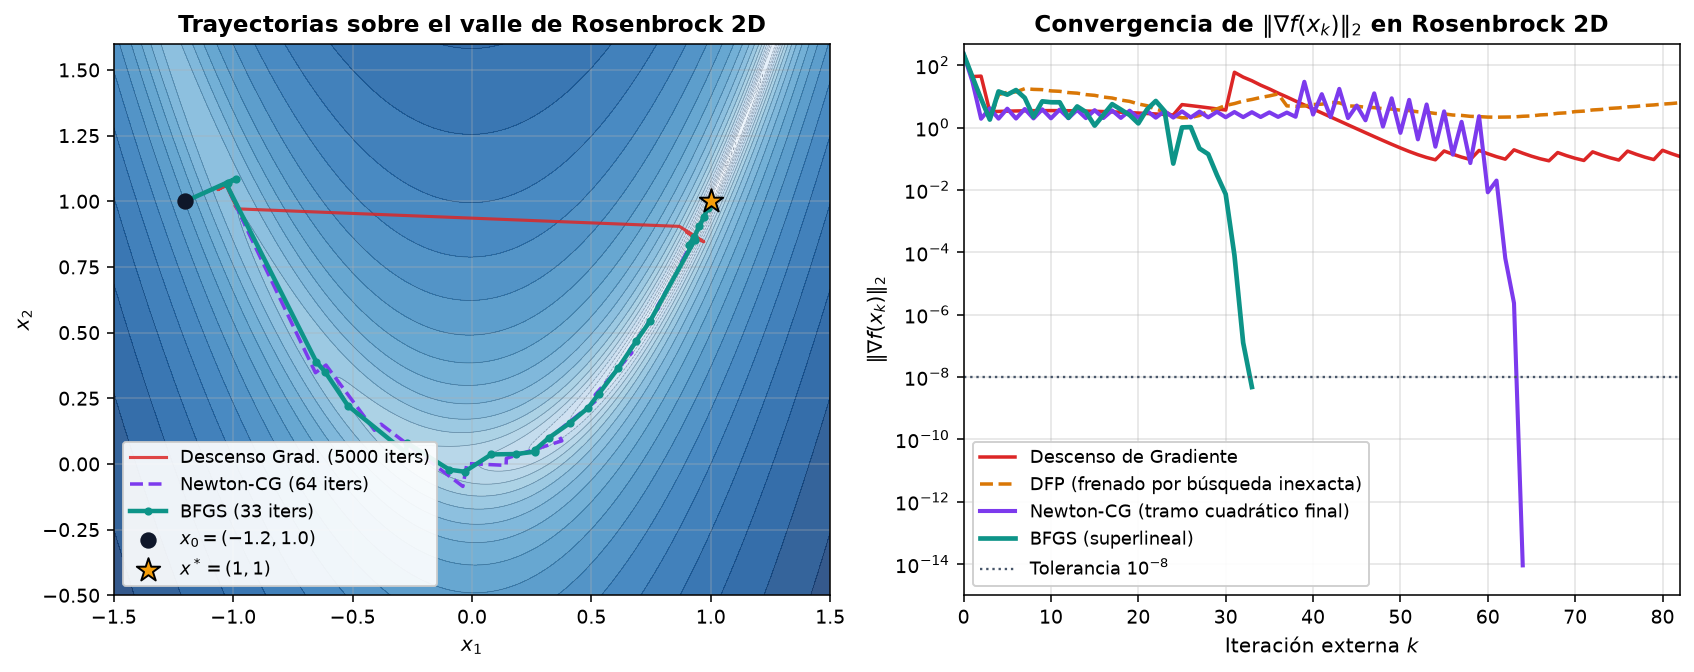

In [4]:
def rosen_f(x):
    return (1.0 - x[0])**2 + 100.0 * (x[1] - x[0]**2)**2

def rosen_g(x):
    return np.array([
        -2.0 * (1.0 - x[0]) - 400.0 * x[0] * (x[1] - x[0]**2),
        200.0 * (x[1] - x[0]**2)
    ])

def rosen_H(x):
    return np.array([
        [2.0 - 400.0 * (x[1] - 3.0 * x[0]**2), -400.0 * x[0]],
        [-400.0 * x[0], 200.0]
    ])

def rosen_hessp_exact(x, d, gx=None):
    return rosen_H(x) @ d

rosen_hessp_fd = make_fd_hessp(rosen_g)
x0_r2 = np.array([-1.2, 1.0])

_, h_gd, s_gd       = descenso_gradiente(rosen_f, rosen_g, x0_r2, tol=1e-8, max_iter=5000)
_, h_dfp, s_dfp     = cuasi_newton_dfp(rosen_f, rosen_g, x0_r2, tol=1e-8, max_iter=500)
_, h_bfgs, s_bfgs   = cuasi_newton_bfgs(rosen_f, rosen_g, x0_r2, tol=1e-8, max_iter=500, track_eigs=True)
_, h_ncg, s_ncg     = newton_cg(rosen_f, rosen_g, rosen_hessp_exact, x0_r2, tol=1e-8, max_iter=200)
_, h_ncgfd, s_ncgfd = newton_cg(rosen_f, rosen_g, rosen_hessp_fd, x0_r2, tol=1e-8, max_iter=200)

res_scipy_bfgs = minimize(rosen_f, x0_r2, jac=rosen_g, method="BFGS", tol=1e-8)
res_scipy_ncg  = minimize(rosen_f, x0_r2, jac=rosen_g, hessp=lambda x, p: rosen_H(x) @ p, method="Newton-CG", tol=1e-8)

print(f"{'Método':<22} | {'Iters':>5} | {'Eval f':>6} | {'Eval g':>6} | {'H*d':>5} | {'Curv<0':>6} | {'f(x_k)':>10} | {'||grad||':>10}")
print("-" * 92)
rows_p1 = [
    ("Descenso Gradiente",  s_gd["iters"],    s_gd["ef"],    s_gd["eg"],    0,            0,             h_gd[-1]["f"],    h_gd[-1]["gnorm"]),
    ("Cuasi-Newton DFP",    s_dfp["iters"],   s_dfp["ef"],   s_dfp["eg"],   0,            0,             h_dfp[-1]["f"],   h_dfp[-1]["gnorm"]),
    ("Cuasi-Newton BFGS",   s_bfgs["iters"],  s_bfgs["ef"],  s_bfgs["eg"],  0,            0,             h_bfgs[-1]["f"],  h_bfgs[-1]["gnorm"]),
    ("Newton-CG (exacto)",  s_ncg["iters"],   s_ncg["ef"],   s_ncg["eg"],   s_ncg["hv"],  s_ncg["neg"],  h_ncg[-1]["f"],   h_ncg[-1]["gnorm"]),
    ("Newton-CG (FD libre)",s_ncgfd["iters"], s_ncgfd["ef"], s_ncgfd["eg"], s_ncgfd["hv"],s_ncgfd["neg"],h_ncgfd[-1]["f"], h_ncgfd[-1]["gnorm"]),
    ("SciPy BFGS (ref.)",   res_scipy_bfgs.nit, res_scipy_bfgs.nfev, res_scipy_bfgs.njev, 0, 0, res_scipy_bfgs.fun, float(np.linalg.norm(res_scipy_bfgs.jac))),
    ("SciPy Newton-CG",     res_scipy_ncg.nit,  res_scipy_ncg.nfev,  res_scipy_ncg.njev,  res_scipy_ncg.nhev, 0, res_scipy_ncg.fun, float(np.linalg.norm(res_scipy_ncg.jac))),
]
for name, it, ef, eg, hv, neg, fv, gn in rows_p1:
    print(f"{name:<22} | {it:5d} | {ef:6d} | {eg:6d} | {hv:5d} | {neg:6d} | {fv:10.2e} | {gn:10.2e}")

print("\nTraza BFGS (verificando curvatura s_k^T y_k > 0 y definitud positiva lambda_min(H_k) > 0):")
print(f"{'k':>3} | {'x1':>9} | {'x2':>9} | {'f(x_k)':>10} | {'||grad||':>10} | {'alpha_k':>7} | {'s^T y':>10} | {'lmin(H_k)':>10}")
print("-" * 82)
for k in [0, 1, 2, 3, 5, 10, 15, 20, 25, 30, len(h_bfgs)-2, len(h_bfgs)-1]:
    if k < len(h_bfgs):
        r = h_bfgs[k]
        print(f"{k:3d} | {r['x'][0]:+9.5f} | {r['x'][1]:+9.5f} | {r['f']:10.3e} | {r['gnorm']:10.3e} | {r['alpha']:7.4f} | {r['sy']:10.3e} | {r['lmin']:10.3e}")

# Figura 1: Trayectorias + Convergencia semilog
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.9))

X1, X2 = np.meshgrid(np.linspace(-1.5, 1.5, 350), np.linspace(-0.5, 1.6, 350))
Z = np.log10((1.0 - X1)**2 + 100.0 * (X2 - X1**2)**2 + 0.05)
cs = ax1.contourf(X1, X2, Z, levels=22, cmap="Blues", alpha=0.82)
ax1.contour(X1, X2, Z, levels=22, colors="#334155", linewidths=0.35, alpha=0.45)

p_gd   = np.array([r["x"] for r in h_gd[:1200]])
p_bfgs = np.array([r["x"] for r in h_bfgs])
p_ncg  = np.array([r["x"] for r in h_ncg])

ax1.plot(p_gd[:, 0], p_gd[:, 1], color="#dc2626", lw=1.6, alpha=0.85, label=f"Descenso Grad. ({s_gd['iters']} iters)")
ax1.plot(p_ncg[:, 0], p_ncg[:, 1], color="#7c3aed", lw=1.8, ls="--", label=f"Newton-CG ({s_ncg['iters']} iters)")
ax1.plot(p_bfgs[:, 0], p_bfgs[:, 1], color="#0d9488", lw=2.3, marker="o", ms=3.2, label=f"BFGS ({s_bfgs['iters']} iters)")
ax1.scatter([-1.2], [1.0], color="#0f172a", s=55, zorder=6, label=r"$x_0 = (-1.2, 1.0)$")
ax1.scatter([1.0], [1.0], color="#f59e0b", edgecolor="black", marker="*", s=160, zorder=7, label=r"$x^* = (1, 1)$")
ax1.set_xlim(-1.5, 1.5); ax1.set_ylim(-0.5, 1.6)
ax1.set_xlabel(r"$x_1$"); ax1.set_ylabel(r"$x_2$")
ax1.set_title("Trayectorias sobre el valle de Rosenbrock 2D")
ax1.legend(loc="lower left", framealpha=0.92)

ax2.semilogy([r["gnorm"] for r in h_gd[:85]], color="#dc2626", lw=1.8, label="Descenso de Gradiente")
ax2.semilogy([r["gnorm"] for r in h_dfp[:85]], color="#d97706", lw=1.8, ls="--", label="DFP (frenado por búsqueda inexacta)")
ax2.semilogy([r["gnorm"] for r in h_ncg], color="#7c3aed", lw=2.1, label="Newton-CG (tramo cuadrático final)")
ax2.semilogy([r["gnorm"] for r in h_bfgs], color="#0d9488", lw=2.4, label="BFGS (superlineal)")
ax2.axhline(1e-8, color="#475569", ls=":", lw=1.2, label=r"Tolerancia $10^{-8}$")
ax2.set_xlim(0, 82); ax2.set_ylim(1e-15, 5e2)
ax2.set_xlabel("Iteración externa $k$")
ax2.set_ylabel(r"$\|\nabla f(x_k)\|_2$")
ax2.set_title(r"Convergencia de $\|\nabla f(x_k)\|_2$ en Rosenbrock 2D")
ax2.legend(loc="lower left", framealpha=0.92)

plt.tight_layout()
plt.savefig("figuras/fig1_rosenbrock.png", bbox_inches="tight")
plt.show()

## 4. Experimento 2: Curvatura Negativa y Punto Silla (¿Por qué falla Newton puro?)

Consideremos el potencial de doble pozo no convexo:
$$f(x_1, x_2) = x_1^4 - 2x_1^2 + x_2^2 + 0.2\, x_1 x_2$$
que posee un **punto silla** en $(0, 0)$ (donde $\nabla^2 f(0,0)$ tiene un valor propio negativo $\lambda_1 \approx -4.01 < 0$) y dos mínimos globales cerca de $(\pm 1, \mp 0.1)$.
Partiendo de $x_0 = (0.35, 0.8)^T$ —dentro de la región cóncava donde $\partial^2 f / \partial x_1^2 = 12 x_1^2 - 4 < 0$— observamos qué ocurre con:
- **Newton puro**: es **atraído hacia el punto silla** $(0, 0)$ porque la Hessiana indefinida invierte el signo del paso.
- **BFGS**: mantiene $H_k \succ 0$ gracias a Wolfe ($s_k^T y_k > 0$) y escapa hacia el mínimo.
- **Newton-CG**: detecta $d_0^T \nabla^2 f(x_0) d_0 \le 0$, trunca CG tomando $-\nabla f(x_0)$ y escapa hacia el mínimo.

En x0 = [0.35 0.8 ]: autovalores de Hessiana = [-2.53881288  2.00881288]  --> ¡Indefinida (curvatura negativa)!
Newton puro : x_final = (+0.00000, -0.00000), f = -0.00000  [ATRAPADO EN PUNTO SILLA]
BFGS        : x_final = (+1.00250, -0.10025), f = -1.01003, iters = 8  [MINIMO]
Newton-CG   : x_final = (+1.00250, -0.10025), f = -1.01003, iters = 5, curv<0 = 1  [MINIMO]


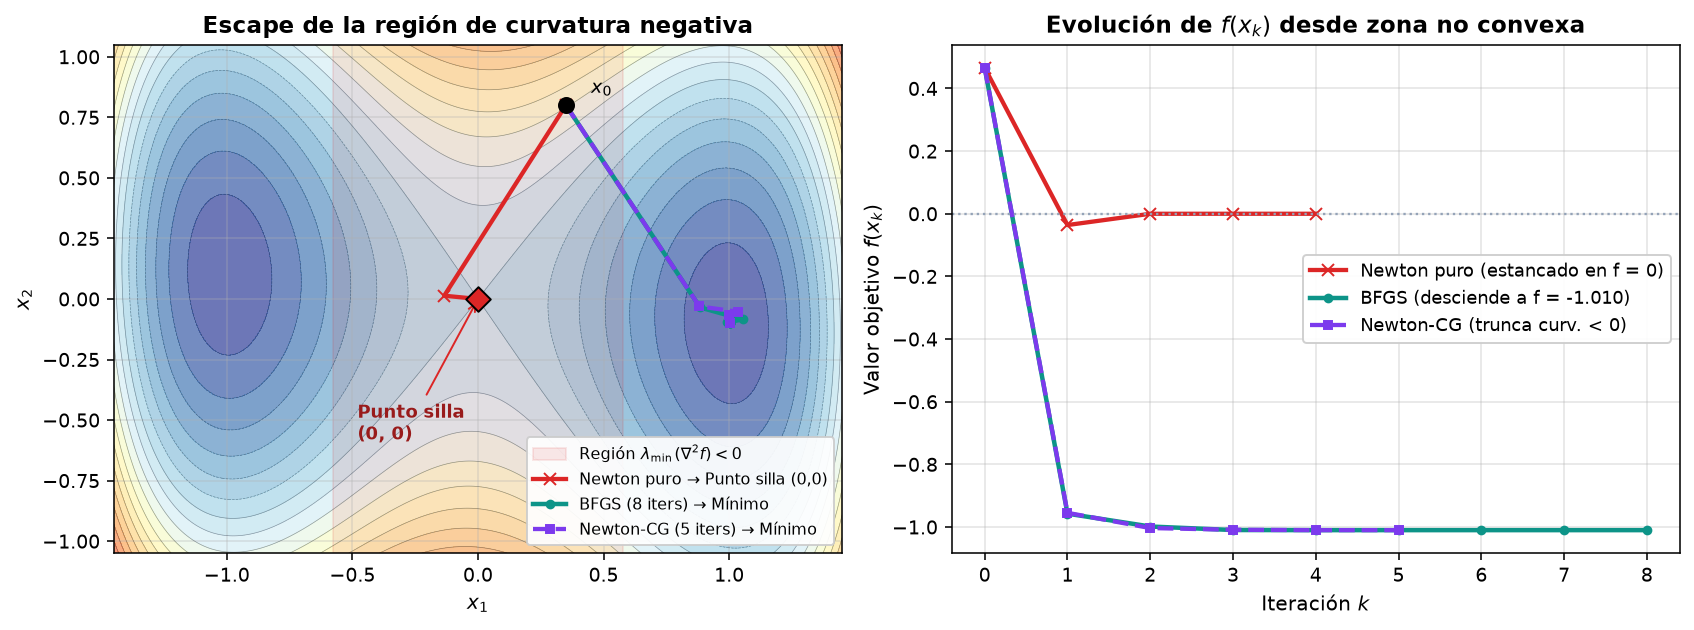

In [5]:
def saddle_f(x):
    return x[0]**4 - 2.0 * x[0]**2 + x[1]**2 + 0.2 * x[0] * x[1]

def saddle_g(x):
    return np.array([4.0 * x[0]**3 - 4.0 * x[0] + 0.2 * x[1], 2.0 * x[1] + 0.2 * x[0]])

def saddle_H(x):
    return np.array([[12.0 * x[0]**2 - 4.0, 0.2], [0.2, 2.0]])

x0_sad = np.array([0.35, 0.80])
eigs0 = np.linalg.eigvalsh(saddle_H(x0_sad))
print(f"En x0 = {x0_sad}: autovalores de Hessiana = {eigs0}  --> ¡Indefinida (curvatura negativa)!")

x_np, h_np = newton_puro(saddle_f, saddle_g, saddle_H, x0_sad, tol=1e-8, max_iter=20)
x_bs, h_bs, s_bs = cuasi_newton_bfgs(saddle_f, saddle_g, x0_sad, tol=1e-8, max_iter=100)
x_ns, h_ns, s_ns = newton_cg(saddle_f, saddle_g, lambda x, d, gx=None: saddle_H(x) @ d, x0_sad, tol=1e-8, max_iter=100)

print(f"Newton puro : x_final = ({x_np[0]:+.5f}, {x_np[1]:+.5f}), f = {saddle_f(x_np):+.5f}  [ATRAPADO EN PUNTO SILLA]")
print(f"BFGS        : x_final = ({x_bs[0]:+.5f}, {x_bs[1]:+.5f}), f = {saddle_f(x_bs):+.5f}, iters = {s_bs['iters']}  [MINIMO]")
print(f"Newton-CG   : x_final = ({x_ns[0]:+.5f}, {x_ns[1]:+.5f}), f = {saddle_f(x_ns):+.5f}, iters = {s_ns['iters']}, curv<0 = {s_ns['neg']}  [MINIMO]")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.6))
X1, X2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.1, 1.1, 300))
Z = X1**4 - 2.0 * X1**2 + X2**2 + 0.2 * X1 * X2
ax1.contourf(X1, X2, Z, levels=24, cmap="RdYlBu_r", alpha=0.72)
ax1.contour(X1, X2, Z, levels=24, colors="#1e293b", linewidths=0.35, alpha=0.45)

# Sombrear region de curvatura negativa (12 x1^2 - 4 < 0 => |x1| < 1/sqrt(3))
lim_nc = 1.0 / np.sqrt(3.0)
ax1.axvspan(-lim_nc, lim_nc, color="#dc2626", alpha=0.10, label=r"Región $\lambda_{\min}(\nabla^2 f) < 0$")

t_np = np.array([r["x"] for r in h_np])
t_bs = np.array([r["x"] for r in h_bs])
t_ns = np.array([r["x"] for r in h_ns])

ax1.plot(t_np[:, 0], t_np[:, 1], color="#dc2626", lw=2.2, marker="x", ms=6, label="Newton puro → Punto silla (0,0)")
ax1.plot(t_bs[:, 0], t_bs[:, 1], color="#0d9488", lw=2.3, marker="o", ms=4, label=f"BFGS ({s_bs['iters']} iters) → Mínimo")
ax1.plot(t_ns[:, 0], t_ns[:, 1], color="#7c3aed", lw=2.2, ls="--", marker="s", ms=4, label=f"Newton-CG ({s_ns['iters']} iters) → Mínimo")
ax1.scatter([0.0], [0.0], color="#dc2626", edgecolor="black", marker="D", s=80, zorder=7)
ax1.scatter([x0_sad[0]], [x0_sad[1]], color="black", s=60, zorder=7)
ax1.annotate("Punto silla\n(0, 0)", xy=(0, 0), xytext=(-0.48, -0.58), arrowprops=dict(arrowstyle="->", color="#dc2626"), fontsize=9, fontweight="bold", color="#991b1b")
ax1.annotate(r"$x_0$", xy=(x0_sad[0], x0_sad[1]), xytext=(0.45, 0.85), fontsize=10, fontweight="bold")
ax1.set_xlim(-1.45, 1.45); ax1.set_ylim(-1.05, 1.05)
ax1.set_xlabel(r"$x_1$"); ax1.set_ylabel(r"$x_2$")
ax1.set_title("Escape de la región de curvatura negativa")
ax1.legend(loc="lower right", fontsize=8.4, framealpha=0.92)

ax2.plot([r["f"] for r in h_np], color="#dc2626", lw=2.2, marker="x", ms=6, label="Newton puro (estancado en f = 0)")
ax2.plot([r["f"] for r in h_bs], color="#0d9488", lw=2.3, marker="o", ms=4, label="BFGS (desciende a f = -1.010)")
ax2.plot([r["f"] for r in h_ns], color="#7c3aed", lw=2.2, ls="--", marker="s", ms=4, label="Newton-CG (trunca curv. < 0)")
ax2.axhline(0.0, color="#94a3b8", ls=":", lw=1.2)
ax2.set_xlabel("Iteración $k$")
ax2.set_ylabel(r"Valor objetivo $f(x_k)$")
ax2.set_title(r"Evolución de $f(x_k)$ desde zona no convexa")
ax2.legend(loc="right", framealpha=0.92)

plt.tight_layout()
plt.savefig("figuras/fig2_curvatura_negativa.png", bbox_inches="tight")
plt.show()

## 5. Experimento 3: Cuadrática Mal Condicionada, *Oversolving* y Escalado a Alta Dimensión

Evaluamos tres fenómenos críticos en optimización numérica de gran escala:
1. **Cuadrática mal condicionada** ($n = 50$, $\kappa(A) = 10^3$): GD vs DFP vs BFGS vs L-BFGS vs Newton-CG.
2. **Secuencia de forzamiento $\eta_k$ y *oversolving*** en Newton-CG sobre un problema elíptico no lineal de dimensión $n = 150$.
3. **Escalado de tiempo y memoria** al aumentar $n \in \{20, 80, 200, 400\}$: comparando **BFGS denso** ($O(n^2)$), **L-BFGS** ($O(mn)$) y **Newton-CG** ($O(n)$).

=== CUADRÁTICA MAL CONDICIONADA (n=50, kappa=10^3) ===
Descenso Gradiente   | iters=3000 | ef=29877 | eg=3001 | H*d=   0 | ||g||=3.38e-03
DFP                  | iters= 500 | ef=  508 | eg= 501 | H*d=   0 | ||g||=1.80e+00
BFGS                 | iters= 217 | ef=  225 | eg= 218 | H*d=   0 | ||g||=7.16e-09
L-BFGS (m=10)        | iters= 395 | ef=  533 | eg= 509 | H*d=   0 | ||g||=9.99e-09
Newton-CG            | iters=  10 | ef=   11 | eg=  11 | H*d= 217 | ||g||=2.51e-09

=== FENÓMENO DE OVERSOLVING EN NEWTON-CG (n=150) ===
Fijo eta = 0.5 (lineal)            | iters=23 | H*d= 117 | t=  7.3 ms | ||g||=9.58e-10
Fijo eta = 1e-1                    | iters=10 | H*d= 133 | t=  5.2 ms | ||g||=1.06e-10
Fijo eta = 1e-8 (casi exacto)      | iters= 5 | H*d= 294 | t=  9.7 ms | ||g||=2.24e-12
Adaptativo sqrt(||g||) (superl.)   | iters= 7 | H*d= 114 | t=  4.1 ms | ||g||=1.23e-10
Adaptativo ||g|| (cuadrático)      | iters= 5 | H*d= 124 | t=  4.1 ms | ||g||=5.32e-12

=== ESCALADO EN DIMENSIÓN (PROBLEMA ELÍP

n=400 | BFGS: 189 it (1135.7 ms,  1250.0 KB) | L-BFGS:  89 it ( 27.7 ms,  62.5 KB) | Newton-CG:  7 it,  116 H*d (  6.9 ms, 12.5 KB)


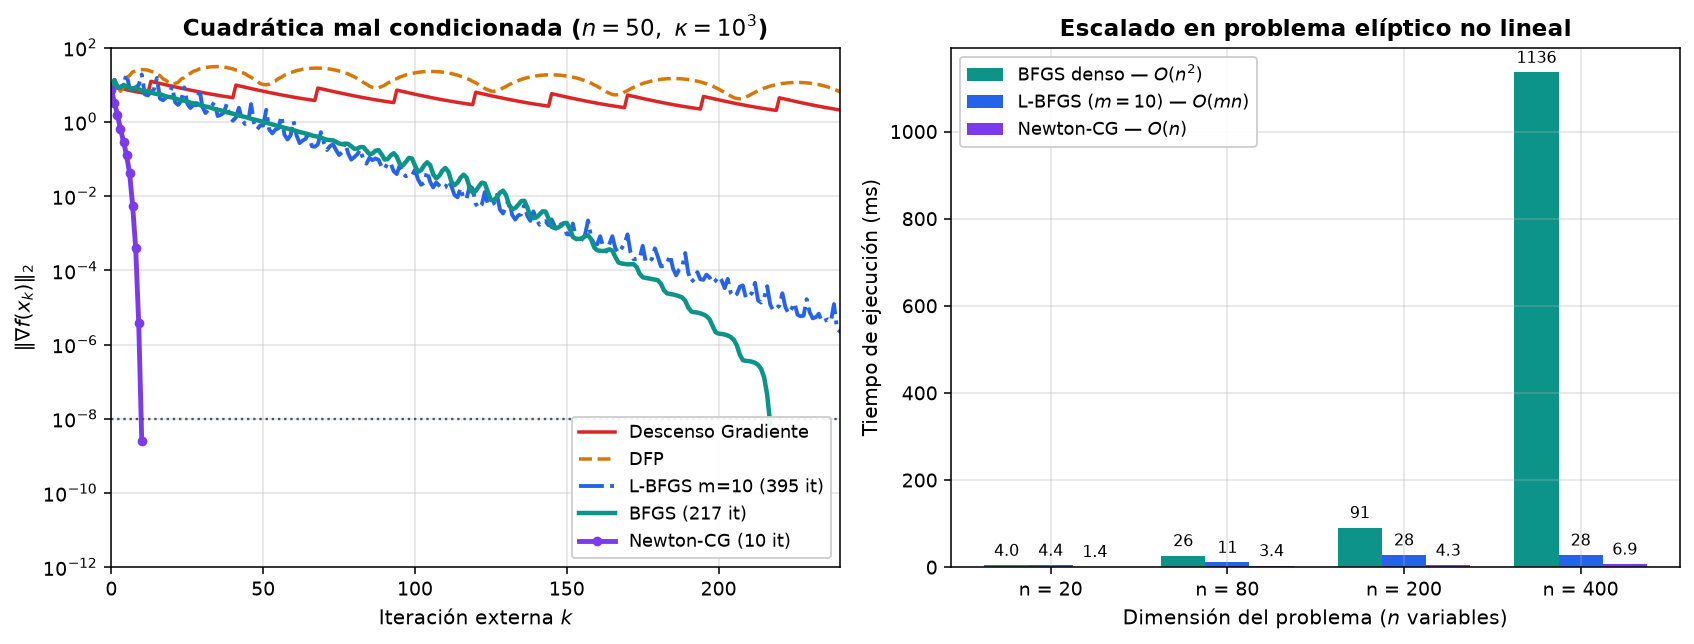


Resultados guardados en figuras/resultados_resumen.json


In [6]:
# 5A. Cuadratica mal condicionada n=50, kappa=1000
n_q = 50
eigs_q = np.logspace(0, 3, n_q)
b_q = np.ones(n_q)
q_f = lambda x: 0.5 * float(np.sum(eigs_q * x * x)) - float(np.dot(b_q, x))
q_g = lambda x: eigs_q * x - b_q
q_hv = lambda x, d, gx=None: eigs_q * d
x0_q = np.zeros(n_q)

_, hq_gd, sq_gd       = descenso_gradiente(q_f, q_g, x0_q, tol=1e-8, max_iter=3000)
_, hq_dfp, sq_dfp     = cuasi_newton_dfp(q_f, q_g, x0_q, tol=1e-8, max_iter=500)
_, hq_bfgs, sq_bfgs   = cuasi_newton_bfgs(q_f, q_g, x0_q, tol=1e-8, max_iter=500)
_, hq_lbfgs, sq_lbfgs = l_bfgs(q_f, q_g, x0_q, m=10, tol=1e-8, max_iter=500)
_, hq_ncg, sq_ncg     = newton_cg(q_f, q_g, q_hv, x0_q, tol=1e-8, max_iter=100, max_cg=100)

print("=== CUADRÁTICA MAL CONDICIONADA (n=50, kappa=10^3) ===")
for name, st, hh in [
    ("Descenso Gradiente", sq_gd, hq_gd),
    ("DFP",                sq_dfp, hq_dfp),
    ("BFGS",               sq_bfgs, hq_bfgs),
    ("L-BFGS (m=10)",      sq_lbfgs, hq_lbfgs),
    ("Newton-CG",          sq_ncg, hq_ncg),
]:
    hv_s = st.get("hv", 0)
    print(f"{name:<20} | iters={st['iters']:4d} | ef={st['ef']:5d} | eg={st['eg']:4d} | H*d={hv_s:4d} | ||g||={hh[-1]['gnorm']:.2e}")

# 5B. Problema eliptico no lineal variacional:
# min 0.5 sum (x_{i+1} - x_i)^2 + 0.005 sum x_i^2 + 0.02 sum (exp(x_i) - x_i - 1) - sum (0.1 h x_i)
def make_nl_elliptic(n):
    h = 1.0 / (n + 1)
    def f(x):
        dx = np.diff(np.concatenate(([0.0], x, [0.0])))
        return 0.5 * float(np.dot(dx, dx)) + 0.005 * float(np.dot(x, x)) + 0.02 * float(np.sum(np.exp(x) - x - 1.0)) - 0.1 * h * float(np.sum(x))
    def g(x):
        out = 2.0 * x
        out[:-1] -= x[1:]
        out[1:]  -= x[:-1]
        return out + 0.01 * x + 0.02 * (np.exp(x) - 1.0) - 0.1 * h
    def hessp(x, d, gx=None):
        out = 2.0 * d
        out[:-1] -= d[1:]
        out[1:]  -= d[:-1]
        return out + (0.01 + 0.02 * np.exp(x)) * d
    return f, g, hessp

# Prueba de oversolving en Newton-CG (n=150)
f150, g150, hv150 = make_nl_elliptic(150)
x0_150 = 1.5 * np.sin(np.pi * np.arange(1, 151) / 151.0)
print("\n=== FENÓMENO DE OVERSOLVING EN NEWTON-CG (n=150) ===")
oversolving_rows = []
for label, forc in [
    ("Fijo eta = 0.5 (lineal)",        0.5),
    ("Fijo eta = 1e-1",                0.1),
    ("Fijo eta = 1e-8 (casi exacto)",  1e-8),
    ("Adaptativo sqrt(||g||) (superl.)", "superlinear"),
    ("Adaptativo ||g|| (cuadrático)",  "quadratic"),
]:
    t0 = time.perf_counter()
    _, hh, st = newton_cg(f150, g150, hv150, x0_150, tol=1e-9, max_iter=60, max_cg=400, forcing=forc)
    dt = (time.perf_counter() - t0) * 1000
    oversolving_rows.append((label, st["iters"], st["hv"], dt, hh[-1]["gnorm"]))
    print(f"{label:<34} | iters={st['iters']:2d} | H*d={st['hv']:4d} | t={dt:5.1f} ms | ||g||={hh[-1]['gnorm']:.2e}")

# 5C. Escalado en dimension n = 20, 80, 200, 400
dims = [20, 80, 200, 400]
scaling_rows = []
print("\n=== ESCALADO EN DIMENSIÓN (PROBLEMA ELÍPTICO NO LINEAL) ===")
for n_dim in dims:
    fn, gn, hvn = make_nl_elliptic(n_dim)
    x0_n = 1.5 * np.sin(np.pi * np.arange(1, n_dim + 1) / (n_dim + 1))

    t0 = time.perf_counter()
    _, hb, sb = cuasi_newton_bfgs(fn, gn, x0_n, tol=1e-8, max_iter=600)
    tb = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    _, hlb, slb = l_bfgs(fn, gn, x0_n, m=10, tol=1e-8, max_iter=600)
    tlb = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    _, hnc, snc = newton_cg(fn, gn, hvn, x0_n, tol=1e-8, max_iter=100, max_cg=2*n_dim)
    tnc = (time.perf_counter() - t0) * 1000

    mem_b  = n_dim * n_dim * 8 / 1024.0
    mem_lb = 2 * 10 * n_dim * 8 / 1024.0
    mem_nc = 4 * n_dim * 8 / 1024.0
    scaling_rows.append({
        "n": n_dim,
        "bfgs_it": sb["iters"], "bfgs_eg": sb["eg"], "bfgs_ms": tb, "bfgs_kb": mem_b,
        "lbfgs_it": slb["iters"], "lbfgs_eg": slb["eg"], "lbfgs_ms": tlb, "lbfgs_kb": mem_lb,
        "ncg_it": snc["iters"], "ncg_hv": snc["hv"], "ncg_ms": tnc, "ncg_kb": mem_nc,
    })
    print(f"n={n_dim:3d} | BFGS: {sb['iters']:3d} it ({tb:6.1f} ms, {mem_b:7.1f} KB) | L-BFGS: {slb['iters']:3d} it ({tlb:5.1f} ms, {mem_lb:5.1f} KB) | Newton-CG: {snc['iters']:2d} it, {snc['hv']:4d} H*d ({tnc:5.1f} ms, {mem_nc:4.1f} KB)")

# Figura 3: Cuadratica mal condicionada + Escalado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.7))

ax1.semilogy([r["gnorm"] for r in hq_gd[:250]], color="#dc2626", lw=1.8, label="Descenso Gradiente")
ax1.semilogy([r["gnorm"] for r in hq_dfp[:250]], color="#d97706", lw=1.8, ls="--", label="DFP")
ax1.semilogy([r["gnorm"] for r in hq_lbfgs[:250]], color="#2563eb", lw=2.0, ls="-.", label=f"L-BFGS m=10 ({sq_lbfgs['iters']} it)")
ax1.semilogy([r["gnorm"] for r in hq_bfgs[:250]], color="#0d9488", lw=2.3, label=f"BFGS ({sq_bfgs['iters']} it)")
ax1.semilogy([r["gnorm"] for r in hq_ncg], color="#7c3aed", lw=2.5, marker="o", ms=4, label=f"Newton-CG ({sq_ncg['iters']} it)")
ax1.axhline(1e-8, color="#475569", ls=":", lw=1.2)
ax1.set_xlim(0, 240); ax1.set_ylim(1e-12, 1e2)
ax1.set_xlabel("Iteración externa $k$")
ax1.set_ylabel(r"$\|\nabla f(x_k)\|_2$")
ax1.set_title(r"Cuadrática mal condicionada ($n=50,\ \kappa=10^3$)")
ax1.legend(loc="lower right", framealpha=0.92)

x_idx = np.arange(len(dims))
w = 0.25
t_bfgs_arr  = [r["bfgs_ms"]  for r in scaling_rows]
t_lbfgs_arr = [r["lbfgs_ms"] for r in scaling_rows]
t_ncg_arr   = [r["ncg_ms"]   for r in scaling_rows]

b1 = ax2.bar(x_idx - w, t_bfgs_arr,  width=w, color="#0d9488", label=r"BFGS denso — $O(n^2)$")
b2 = ax2.bar(x_idx,     t_lbfgs_arr, width=w, color="#2563eb", label=r"L-BFGS ($m=10$) — $O(mn)$")
b3 = ax2.bar(x_idx + w, t_ncg_arr,   width=w, color="#7c3aed", label=r"Newton-CG — $O(n)$")
for bars in (b1, b2, b3):
    for bar in bars:
        hval = bar.get_height()
        ax2.annotate(f"{hval:.0f}" if hval >= 10 else f"{hval:.1f}",
                     xy=(bar.get_x() + bar.get_width() / 2, hval),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)
ax2.set_xticks(x_idx); ax2.set_xticklabels([f"n = {d}" for d in dims])
ax2.set_ylabel("Tiempo de ejecución (ms)")
ax2.set_xlabel("Dimensión del problema ($n$ variables)")
ax2.set_title("Escalado en problema elíptico no lineal")
ax2.legend(loc="upper left", framealpha=0.92)

plt.tight_layout()
plt.savefig("figuras/fig3_cuadratica_escalado.png", bbox_inches="tight")
plt.show()

# Guardar resumen JSON para trazabilidad exacta con el informe y la presentacion
summary = {
    "rosenbrock_2d": [{"metodo": r[0], "iters": int(r[1]), "ef": int(r[2]), "eg": int(r[3]), "hv": int(r[4]), "neg": int(r[5]), "f": float(r[6]), "gnorm": float(r[7])} for r in rows_p1],
    "bfgs_trace_2d": [{"k": k, "x1": float(h_bfgs[k]["x"][0]), "x2": float(h_bfgs[k]["x"][1]), "f": float(h_bfgs[k]["f"]), "gnorm": float(h_bfgs[k]["gnorm"]), "alpha": float(h_bfgs[k]["alpha"]), "sy": float(h_bfgs[k]["sy"]), "lmin": float(h_bfgs[k]["lmin"])} for k in [0, 1, 2, 3, 5, 10, 15, 20, 25, 30, len(h_bfgs)-2, len(h_bfgs)-1] if k < len(h_bfgs)],
    "saddle_2d": {
        "newton_puro": {"x": x_np.tolist(), "f": float(saddle_f(x_np)), "iters": len(h_np)-1},
        "bfgs": {"x": x_bs.tolist(), "f": float(saddle_f(x_bs)), "iters": s_bs["iters"]},
        "newton_cg": {"x": x_ns.tolist(), "f": float(saddle_f(x_ns)), "iters": s_ns["iters"], "neg": s_ns["neg"]},
    },
    "quadratic_50": {
        "gd": {"iters": sq_gd["iters"], "ef": sq_gd["ef"], "eg": sq_gd["eg"], "gnorm": hq_gd[-1]["gnorm"]},
        "dfp": {"iters": sq_dfp["iters"], "ef": sq_dfp["ef"], "eg": sq_dfp["eg"], "gnorm": hq_dfp[-1]["gnorm"]},
        "bfgs": {"iters": sq_bfgs["iters"], "ef": sq_bfgs["ef"], "eg": sq_bfgs["eg"], "gnorm": hq_bfgs[-1]["gnorm"]},
        "lbfgs": {"iters": sq_lbfgs["iters"], "ef": sq_lbfgs["ef"], "eg": sq_lbfgs["eg"], "gnorm": hq_lbfgs[-1]["gnorm"]},
        "newton_cg": {"iters": sq_ncg["iters"], "ef": sq_ncg["ef"], "eg": sq_ncg["eg"], "hv": sq_ncg["hv"], "gnorm": hq_ncg[-1]["gnorm"]},
    },
    "oversolving_150": [{"label": r[0], "iters": int(r[1]), "hv": int(r[2]), "ms": float(r[3]), "gnorm": float(r[4])} for r in oversolving_rows],
    "scaling": scaling_rows,
}
with open("figuras/resultados_resumen.json", "w", encoding="utf-8") as fp:
    json.dump(summary, fp, indent=2, ensure_ascii=False)
print("\nResultados guardados en figuras/resultados_resumen.json")